<a href="https://colab.research.google.com/github/MilagrosBrucellaria/Preentrega9-pipeline-ausentismo-laboral/blob/main/Preentrega9_Pipeline_Ausentismo_Milagros_Brucellaria.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pipeline de Machine Learning para la predicción del ausentismo laboral

## Preentrega: Pipeline y prevención de Data Leakage

**Estudiante:** Milagros Belén Brucellaria  
**Curso:** Data Science  
**Tipo de aprendizaje:** Machine Learning supervisado  
**Tipo de problema:** Regresión  
**Variable objetivo:** Absenteeism Time in Hours  

---

## Descripción general

El ausentismo laboral representa un desafío relevante para las organizaciones, ya que puede afectar la productividad, la planificación de la dotación, la continuidad de las operaciones y la distribución de la carga de trabajo.

El objetivo de este proyecto es construir un pipeline de Machine Learning que permita predecir la cantidad de horas de ausentismo laboral a partir de variables personales, demográficas y relacionadas con el contexto de trabajo.

Para garantizar un proceso reproducible y evitar la fuga de datos, se utilizarán las clases `Pipeline` y `ColumnTransformer` de Scikit-Learn. Estas herramientas permiten encapsular el preprocesamiento y el modelo predictivo dentro de un único objeto.

El pipeline incluirá:

- Imputación de valores faltantes.
- Escalado de variables numéricas.
- Imputación de variables categóricas.
- Codificación mediante One-Hot Encoding.
- Entrenamiento de un modelo de regresión.
- Evaluación sobre un conjunto de prueba.
- Predicción sobre nuevos datos.
- Persistencia del pipeline mediante `joblib`.

## 1. Objetivos del proyecto

### Objetivo general

Desarrollar un pipeline de Machine Learning capaz de predecir la cantidad de horas de ausentismo laboral, integrando el preprocesamiento de variables numéricas y categóricas con un modelo de regresión.

### Objetivos específicos

1. Cargar e inspeccionar el dataset de ausentismo laboral.
2. Identificar la variable objetivo y las variables predictoras.
3. Diferenciar variables numéricas y categóricas.
4. Dividir los datos en conjuntos de entrenamiento y prueba antes de ajustar los transformadores.
5. Construir pipelines específicos para cada tipo de variable.
6. Integrar los pipelines mediante un `ColumnTransformer`.
7. Incorporar el preprocesamiento y el modelo en un pipeline final.
8. Evaluar el desempeño del modelo mediante métricas de regresión.
9. Verificar que el pipeline pueda predecir sobre nuevos datos.
10. Exportar el pipeline entrenado mediante la librería `joblib`.

## 2. Definición del problema de Machine Learning

El proyecto corresponde a un problema de Machine Learning supervisado porque el dataset contiene una variable objetivo conocida que se utilizará durante el entrenamiento.

La variable objetivo es `Absenteeism Time in Hours`, que representa la cantidad de horas de ausencia registradas.

Debido a que esta variable es cuantitativa y puede asumir diferentes valores numéricos, el problema se abordará como una tarea de regresión.

Las variables predictoras incluyen información relacionada con:

- Motivo de la ausencia.
- Edad.
- Distancia al trabajo.
- Gastos de transporte.
- Carga laboral promedio.
- Índice de masa corporal.
- Nivel educativo.
- Cantidad de hijos.
- Cantidad de mascotas.

El modelo buscará aprender las relaciones existentes entre estas características y la cantidad de horas de ausentismo.

In [1]:
# Manipulación de datos
import pandas as pd
import numpy as np

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns

# División de datos
from sklearn.model_selection import train_test_split

# Preprocesamiento
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Modelo
from sklearn.linear_model import LinearRegression

# Métricas de evaluación
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Persistencia del pipeline
import joblib

# Utilidades del sistema
import os

print("Librerías importadas correctamente.")

Librerías importadas correctamente.


In [2]:
# Semilla utilizada para reproducibilidad
RANDOM_STATE = 42

# Configuración visual
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")

print("Configuración inicial completada.")

Configuración inicial completada.


## 3. Carga del dataset

El dataset será cargado en Google Colab utilizando la librería `pandas`. Luego de la carga, se realizarán controles iniciales para verificar la cantidad de registros, columnas, tipos de datos y posibles problemas de calidad.

En esta etapa todavía no se aplicará ninguna transformación sobre los datos.

In [3]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [4]:
ruta_archivo = "/content/drive/MyDrive/Data Science/Data Science II/Absenteeism-data.csv"

df = pd.read_csv(ruta_archivo, sep=";")

print("Dataset cargado correctamente.")
print("Dimensiones:", df.shape)

df.head()

Dataset cargado correctamente.
Dimensiones: (700, 12)


,ID,Reason for Absence,Date,Transportation Expense,Distance to Work,Age,Daily Work Load Average,Body Mass Index,Education,Children,Pets,Absenteeism Time in Hours
0,11,26,7/7/2015,289,36,33,239.554,30,1,2,1,4
1,36,0,14/7/2015,118,13,50,239.554,31,1,1,0,0
2,3,23,15/7/2015,179,51,38,239.554,31,1,0,0,2
3,7,7,16/7/2015,279,5,39,239.554,24,1,2,0,4
4,11,23,23/7/2015,289,36,33,239.554,30,1,2,1,2


In [5]:
#Inspección inicial
print("Dimensiones del dataset:")
print(df.shape)

print("\nPrimeros cinco registros:")
display(df.head())

print("\nÚltimos cinco registros:")
display(df.tail())

print("\nNombres de las columnas:")
for numero, columna in enumerate(df.columns, start=1):
    print(f"{numero}. {columna}")

Dimensiones del dataset:
(700, 12)

Primeros cinco registros:


,ID,Reason for Absence,Date,Transportation Expense,Distance to Work,Age,Daily Work Load Average,Body Mass Index,Education,Children,Pets,Absenteeism Time in Hours
0,11,26,7/7/2015,289,36,33,239.554,30,1,2,1,4
1,36,0,14/7/2015,118,13,50,239.554,31,1,1,0,0
2,3,23,15/7/2015,179,51,38,239.554,31,1,0,0,2
3,7,7,16/7/2015,279,5,39,239.554,24,1,2,0,4
4,11,23,23/7/2015,289,36,33,239.554,30,1,2,1,2



Últimos cinco registros:


,ID,Reason for Absence,Date,Transportation Expense,Distance to Work,Age,Daily Work Load Average,Body Mass Index,Education,Children,Pets,Absenteeism Time in Hours
695,17,10,23/5/2018,179,22,40,237.656,22,2,2,0,8
696,28,6,23/5/2018,225,26,28,237.656,24,1,1,2,3
697,18,10,24/5/2018,330,16,28,237.656,25,2,0,0,8
698,25,23,24/5/2018,235,16,32,237.656,25,3,0,0,2
699,15,28,31/5/2018,291,31,40,237.656,25,1,1,1,2



Nombres de las columnas:
1. ID
2. Reason for Absence
3. Date
4. Transportation Expense
5. Distance to Work
6. Age
7. Daily Work Load Average
8. Body Mass Index
9. Education
10. Children
11. Pets
12. Absenteeism Time in Hours


## 4. Inspección de tipos de datos y calidad

Una vez cargado correctamente el dataset, se analiza la estructura de las variables antes de realizar cualquier transformación.

Esta etapa permite distinguir entre el tipo de dato almacenado en Python y el significado estadístico de cada variable. Esta distinción es especialmente importante porque algunas características pueden estar codificadas mediante números, pero representar conceptualmente categorías.

También se revisará la presencia de valores faltantes, valores únicos y registros duplicados antes de construir el pipeline de preprocesamiento.

In [6]:
print("INFORMACIÓN GENERAL DEL DATASET")
print("=" * 50)

df.info()

INFORMACIÓN GENERAL DEL DATASET
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 700 entries, 0 to 699
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   ID                         700 non-null    int64  
 1   Reason for Absence         700 non-null    int64  
 2   Date                       700 non-null    object 
 3   Transportation Expense     700 non-null    int64  
 4   Distance to Work           700 non-null    int64  
 5   Age                        700 non-null    int64  
 6   Daily Work Load Average    700 non-null    float64
 7   Body Mass Index            700 non-null    int64  
 8   Education                  700 non-null    int64  
 9   Children                   700 non-null    int64  
 10  Pets                       700 non-null    int64  
 11  Absenteeism Time in Hours  700 non-null    int64  
dtypes: float64(1), int64(10), object(1)
memory usage: 65.8+ KB


In [7]:
resumen_variables = pd.DataFrame({
    "Variable": df.columns,
    "Tipo_Pandas": df.dtypes.astype(str).values,
    "Valores_No_Nulos": df.notna().sum().values,
    "Valores_Nulos": df.isna().sum().values,
    "Valores_Unicos": df.nunique().values
})

resumen_variables

,Variable,Tipo_Pandas,Valores_No_Nulos,Valores_Nulos,Valores_Unicos
0,ID,int64,700,0,34
1,Reason for Absence,int64,700,0,28
2,Date,object,700,0,432
3,Transportation Expense,int64,700,0,24
4,Distance to Work,int64,700,0,24
5,Age,int64,700,0,21
6,Daily Work Load Average,float64,700,0,35
7,Body Mass Index,int64,700,0,16
8,Education,int64,700,0,4
9,Children,int64,700,0,5


In [8]:
print("CONTROL DE CALIDAD")
print("=" * 50)

print(f"Filas: {df.shape[0]}")
print(f"Columnas: {df.shape[1]}")
print(f"Valores nulos totales: {df.isna().sum().sum()}")
print(f"Registros duplicados: {df.duplicated().sum()}")

print("\nValores nulos por variable:")
display(
    df.isna()
      .sum()
      .sort_values(ascending=False)
      .to_frame(name="Valores_Nulos")
)

CONTROL DE CALIDAD
Filas: 700
Columnas: 12
Valores nulos totales: 0
Registros duplicados: 8

Valores nulos por variable:


,Valores_Nulos
ID,0
Reason for Absence,0
Date,0
Transportation Expense,0
Distance to Work,0
Age,0
Daily Work Load Average,0
Body Mass Index,0
Education,0
Children,0


### Tipo de dato vs. tipo de variable

En Data Science es importante diferenciar el tipo de dato técnico del tipo de variable desde el punto de vista estadístico.

Por ejemplo, una columna puede estar almacenada como `int64` porque contiene números enteros, pero esos números pueden funcionar simplemente como códigos que identifican categorías.

En este dataset:

- `Reason for Absence` utiliza códigos numéricos para representar diferentes motivos de ausencia. Por lo tanto, será considerada una variable categórica.
- `Education` utiliza códigos para representar niveles educativos, por lo que también requiere un tratamiento categórico.
- Variables como `Age`, `Distance to Work`, `Transportation Expense`, `Daily Work Load Average` y `Body Mass Index` representan magnitudes cuantitativas y serán tratadas como variables numéricas.
- `Date` representa una variable temporal y requiere un tratamiento específico antes de incorporarse al modelo.
- `ID` funciona como identificador del registro o empleado y no representa una característica predictiva que deba ser utilizada directamente por el modelo.

Esta clasificación conceptual permitirá definir posteriormente diferentes estrategias de transformación mediante `ColumnTransformer`.

## 5. Preparación y clasificación de las variables

A partir de la exploración inicial se identificaron 700 observaciones y 12 variables. No se encontraron valores faltantes y se detectaron 8 registros duplicados.

Antes de construir el pipeline se define el rol que tendrá cada variable dentro del modelo. Para realizar esta clasificación no se considera únicamente el tipo de dato identificado por Pandas, sino también el significado conceptual de cada característica.

- `Absenteeism Time in Hours`: variable objetivo cuantitativa. Al representar una cantidad de horas, el problema se plantea como una tarea de regresión.
- `ID`: funciona como identificador y no representa una característica predictiva, por lo que será excluida del modelo.
- `Date`: representa información temporal y será transformada para generar características que puedan ser utilizadas por el modelo.
- `Reason for Absence`: aunque está almacenada como `int64`, sus valores representan códigos correspondientes a distintos motivos de ausencia. Por lo tanto, será tratada como variable categórica.
- `Education`: también se encuentra codificada numéricamente, pero sus valores representan categorías de nivel educativo.
- Las variables asociadas con edad, distancia al trabajo, gastos de transporte, carga de trabajo e índice de masa corporal representan magnitudes cuantitativas y serán tratadas como variables numéricas.

Esta clasificación permitirá posteriormente aplicar transformaciones diferentes a cada grupo de variables mediante `ColumnTransformer`.

In [9]:
# Cantidad de registros antes de eliminar duplicados
filas_antes = df.shape[0]

# Eliminación de registros completamente duplicados
df = df.drop_duplicates().reset_index(drop=True)

# Cantidad de registros después de la eliminación
filas_despues = df.shape[0]

print("CONTROL DE DUPLICADOS")
print("=" * 40)
print(f"Registros antes: {filas_antes}")
print(f"Registros después: {filas_despues}")
print(f"Duplicados eliminados: {filas_antes - filas_despues}")


CONTROL DE DUPLICADOS
Registros antes: 700
Registros después: 692
Duplicados eliminados: 8


### Tratamiento de la variable temporal `Date`

La variable `Date` se encuentra originalmente almacenada como texto (`object`). Este formato no puede ser utilizado directamente por un modelo de regresión.

Por este motivo, se convierte la variable al tipo `datetime` y se generan dos nuevas características:

- `Month`: representa el mes en el que ocurrió el registro.
- `DayOfWeek`: representa el día de la semana.

De esta forma se conserva información temporal potencialmente relevante para explicar patrones de ausentismo, evitando ingresar la fecha original como texto en el modelo.

Luego de generar estas características, la columna `Date` original será eliminada.

In [10]:
# Conversión de la variable Date al tipo datetime
df["Date"] = pd.to_datetime(
    df["Date"],
    format="%d/%m/%Y",
    errors="coerce"
)

# Creación de nuevas características temporales
df["Month"] = df["Date"].dt.month
df["DayOfWeek"] = df["Date"].dt.dayofweek

print("CONTROL DE TRANSFORMACIÓN DE FECHA")
print("=" * 45)

print(f"Fechas no convertidas: {df['Date'].isna().sum()}")

print("\nPrimeros registros:")
display(df[["Date", "Month", "DayOfWeek"]].head(10))

CONTROL DE TRANSFORMACIÓN DE FECHA
Fechas no convertidas: 0

Primeros registros:


,Date,Month,DayOfWeek
0,2015-07-07,7,1
1,2015-07-14,7,1
2,2015-07-15,7,2
3,2015-07-16,7,3
4,2015-07-23,7,3
5,2015-07-10,7,4
6,2015-07-17,7,4
7,2015-07-24,7,4
8,2015-07-06,7,0
9,2015-07-13,7,0


In [11]:
# Eliminamos la fecha original porque ya extrajimos
# la información temporal que utilizaremos en el modelo
df = df.drop(columns=["Date"])

print("Columnas disponibles después del tratamiento de Date:")
print("=" * 55)

for numero, columna in enumerate(df.columns, start=1):
    print(f"{numero}. {columna}")

print("\nDimensiones actuales:", df.shape)

Columnas disponibles después del tratamiento de Date:
1. ID
2. Reason for Absence
3. Transportation Expense
4. Distance to Work
5. Age
6. Daily Work Load Average
7. Body Mass Index
8. Education
9. Children
10. Pets
11. Absenteeism Time in Hours
12. Month
13. DayOfWeek

Dimensiones actuales: (692, 13)


## 6. Separación de variables predictoras y variable objetivo

La variable objetivo del proyecto es `Absenteeism Time in Hours`, que representa la cantidad de horas de ausentismo laboral.

La columna identificadora `ID` fue excluida del conjunto de variables predictoras, ya que funciona como un identificador y no representa una característica cuantitativa relevante para la predicción.

Hasta esta instancia no se aplicaron técnicas de imputación, escalado ni codificación. Estas transformaciones serán incorporadas posteriormente dentro del pipeline para evitar fuga de información (`data leakage`).


In [12]:
# Variable objetivo
target = "Absenteeism Time in Hours"

# Variable objetivo
y = df[target]

# Variables predictoras
# Excluimos tanto el target como el identificador ID
X = df.drop(columns=[target, "ID"])

print("SEPARACIÓN DE VARIABLES")
print("=" * 40)

print(f"Dimensiones de X: {X.shape}")
print(f"Dimensiones de y: {y.shape}")

print("\nVariables predictoras:")
for numero, columna in enumerate(X.columns, start=1):
    print(f"{numero}. {columna}")

SEPARACIÓN DE VARIABLES
Dimensiones de X: (692, 11)
Dimensiones de y: (692,)

Variables predictoras:
1. Reason for Absence
2. Transportation Expense
3. Distance to Work
4. Age
5. Daily Work Load Average
6. Body Mass Index
7. Education
8. Children
9. Pets
10. Month
11. DayOfWeek


## 6. Preparación de los datos para Machine Learning

La variable objetivo seleccionada es `Absenteeism Time in Hours`, ya que el propósito del proyecto es predecir la cantidad de horas de ausentismo laboral.

La columna `ID` se mantiene en el dataset original, pero se excluye de las variables predictoras debido a que funciona únicamente como identificador.

Las características se clasifican conceptualmente en variables numéricas y categóricas. Esta clasificación no depende exclusivamente del tipo de dato almacenado en Pandas. Algunas variables, como `Reason for Absence` y `Education`, están representadas mediante números enteros pero funcionan como categorías.

Antes de ajustar cualquier transformación, el dataset se divide en conjuntos de entrenamiento y prueba. Esta secuencia es fundamental para evitar `data leakage`, ya que los parámetros utilizados para imputar, escalar y codificar serán aprendidos exclusivamente a partir del conjunto de entrenamiento.

In [13]:
# ------------------------------------------------------
# 1. SEPARACIÓN DE VARIABLES
# ------------------------------------------------------

target = "Absenteeism Time in Hours"

# Variable objetivo
y = df[target]

# Variables predictoras
# Excluimos target e ID
X = df.drop(columns=[target, "ID"])


# ------------------------------------------------------
# 2. CLASIFICACIÓN DE VARIABLES
# ------------------------------------------------------

numeric_features = [
    "Transportation Expense",
    "Distance to Work",
    "Age",
    "Daily Work Load Average",
    "Body Mass Index",
    "Children",
    "Pets"
]

categorical_features = [
    "Reason for Absence",
    "Education",
    "Month",
    "DayOfWeek"
]


# ------------------------------------------------------
# 3. CONTROL
# ------------------------------------------------------

print("PREPARACIÓN DE VARIABLES")
print("=" * 50)

print(f"Dimensiones de X: {X.shape}")
print(f"Dimensiones de y: {y.shape}")

print(f"\nVariables numéricas: {len(numeric_features)}")
print(f"Variables categóricas: {len(categorical_features)}")
print(f"Total clasificadas: {len(numeric_features) + len(categorical_features)}")
print(f"Total columnas de X: {X.shape[1]}")


# ------------------------------------------------------
# 4. DIVISIÓN TRAIN / TEST
# ------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE
)

print("\nDIVISIÓN TRAIN / TEST")
print("=" * 50)

print(f"X_train: {X_train.shape}")
print(f"X_test:  {X_test.shape}")
print(f"y_train: {y_train.shape}")
print(f"y_test:  {y_test.shape}")

print(f"\nEntrenamiento: {len(X_train) / len(X):.1%}")
print(f"Prueba: {len(X_test) / len(X):.1%}")

PREPARACIÓN DE VARIABLES
Dimensiones de X: (692, 11)
Dimensiones de y: (692,)

Variables numéricas: 7
Variables categóricas: 4
Total clasificadas: 11
Total columnas de X: 11

DIVISIÓN TRAIN / TEST
X_train: (553, 11)
X_test:  (139, 11)
y_train: (553,)
y_test:  (139,)

Entrenamiento: 79.9%
Prueba: 20.1%


## 7. Construcción del pipeline de preprocesamiento

Una vez realizada la división Train/Test, se construyen dos pipelines de preprocesamiento independientes.

### Pipeline numérico

Las variables numéricas atraviesan dos transformaciones:

1. `SimpleImputer`: permite completar posibles valores faltantes utilizando la mediana de cada variable.
2. `StandardScaler`: estandariza las variables para que queden expresadas en una escala comparable.

### Pipeline categórico

Las variables categóricas atraviesan también dos transformaciones:

1. `SimpleImputer`: completa posibles valores faltantes utilizando la categoría más frecuente.
2. `OneHotEncoder`: transforma las categorías en variables binarias que pueden ser interpretadas por el modelo.

Se utiliza `handle_unknown="ignore"` para garantizar que el pipeline pueda procesar categorías nuevas durante la inferencia sin generar errores.

Aunque el dataset actual no presenta valores faltantes, incorporar estrategias de imputación permite construir un pipeline más robusto y reutilizable frente a nuevos datos.

In [14]:
# ------------------------------------------------------
# PIPELINE NUMÉRICO
# ------------------------------------------------------

numeric_pipeline = Pipeline(steps=[
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "scaler",
        StandardScaler()
    )
])


# ------------------------------------------------------
# PIPELINE CATEGÓRICO
# ------------------------------------------------------

categorical_pipeline = Pipeline(steps=[
    (
        "imputer",
        SimpleImputer(strategy="most_frequent")
    ),
    (
        "encoder",
        OneHotEncoder(handle_unknown="ignore")
    )
])

print("Pipeline numérico:")
print(numeric_pipeline)

print("\nPipeline categórico:")
print(categorical_pipeline)

Pipeline numérico:
Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler())])

Pipeline categórico:
Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')),
                ('encoder', OneHotEncoder(handle_unknown='ignore'))])


## 8. Integración mediante ColumnTransformer

Para aplicar automáticamente el tratamiento correspondiente a cada grupo de variables se utiliza `ColumnTransformer`.

Este componente permite aplicar el pipeline numérico únicamente sobre las características numéricas y el pipeline categórico sobre las características categóricas.

De esta manera, toda la lógica de preprocesamiento queda centralizada y puede posteriormente incorporarse al pipeline final de Machine Learning.

In [15]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numeric_pipeline,
            numeric_features
        ),
        (
            "categorical",
            categorical_pipeline,
            categorical_features
        )
    ]
)

print("ColumnTransformer creado correctamente.")
print(preprocessor)

ColumnTransformer creado correctamente.
ColumnTransformer(transformers=[('numeric',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['Transportation Expense', 'Distance to Work',
                                  'Age', 'Daily Work Load Average',
                                  'Body Mass Index', 'Children', 'Pets']),
                                ('categorical',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['Reason for Absence', 'Education', 'Month',
                                 

## 9. Pipeline completo de Machine Learning

El preprocesador se integra con un modelo de `LinearRegression` dentro de un único objeto `Pipeline`.

El pipeline completo será responsable de ejecutar secuencialmente:

1. Imputación de variables numéricas.
2. Escalado de variables numéricas.
3. Imputación de variables categóricas.
4. Codificación One-Hot.
5. Entrenamiento del modelo de regresión.

La principal ventaja de este enfoque es que el preprocesamiento y el modelo permanecen encapsulados dentro del mismo objeto.

El método `.fit()` se ejecutará exclusivamente utilizando los datos de entrenamiento. De esta manera, valores como medianas, categorías frecuentes, parámetros de escalado y categorías del One-Hot Encoder serán aprendidos únicamente a partir de `X_train`, evitando fuga de información desde el conjunto de prueba.

In [16]:
model_pipeline = Pipeline(steps=[
    (
        "preprocessor",
        preprocessor
    ),
    (
        "model",
        LinearRegression()
    )
])

print("PIPELINE COMPLETO")
print("=" * 50)
print(model_pipeline)

PIPELINE COMPLETO
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Transportation Expense',
                                                   'Distance to Work', 'Age',
                                                   'Daily Work Load Average',
                                                   'Body Mass Index',
                                                   'Children', 'Pets']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                        

## 10. Entrenamiento del pipeline

El pipeline completo se ajusta utilizando únicamente los datos pertenecientes al conjunto de entrenamiento.

No se realiza previamente `fit_transform()` sobre el dataset completo. Todas las transformaciones que requieren aprender parámetros se ejecutan internamente cuando se llama al método `.fit()` del pipeline.

Este enfoque garantiza que el conjunto de prueba permanezca independiente del proceso de entrenamiento.

In [17]:
# Entrenamiento utilizando exclusivamente TRAIN
model_pipeline.fit(X_train, y_train)

print("Pipeline entrenado correctamente.")

Pipeline entrenado correctamente.


## 11. Evaluación del modelo

Una vez entrenado el pipeline, se generan predicciones sobre el conjunto de prueba.

Para evaluar un problema de regresión se utilizan las siguientes métricas:

- **MAE (Mean Absolute Error):** representa el error absoluto promedio de las predicciones.
- **RMSE (Root Mean Squared Error):** penaliza con mayor intensidad los errores grandes.
- **R² (Coeficiente de determinación):** indica qué proporción de la variabilidad de la variable objetivo es explicada por el modelo.

Estas métricas se calculan utilizando exclusivamente observaciones que no fueron utilizadas durante el entrenamiento.

In [18]:
# Predicciones del conjunto de prueba
y_pred = model_pipeline.predict(X_test)

# Métricas
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("RESULTADOS DEL MODELO")
print("=" * 50)

print(f"MAE:  {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²:   {r2:.4f}")

RESULTADOS DEL MODELO
MAE:  5.8581
RMSE: 15.0523
R²:   0.0638


In [19]:
resultados = pd.DataFrame({
    "Valor_Real": y_test.values,
    "Valor_Predicho": y_pred
})

resultados["Error_Absoluto"] = abs(
    resultados["Valor_Real"] -
    resultados["Valor_Predicho"]
)

display(resultados.head(15))

,Valor_Real,Valor_Predicho,Error_Absoluto
0,3,2.095951,0.904049
1,2,10.160629,8.160629
2,1,4.702789,3.702789
3,3,5.859547,2.859547
4,120,10.037883,109.962117
5,0,-4.063283,4.063283
6,1,9.979209,8.979209
7,3,15.627717,12.627717
8,3,32.292884,29.292884
9,4,4.387167,0.387167


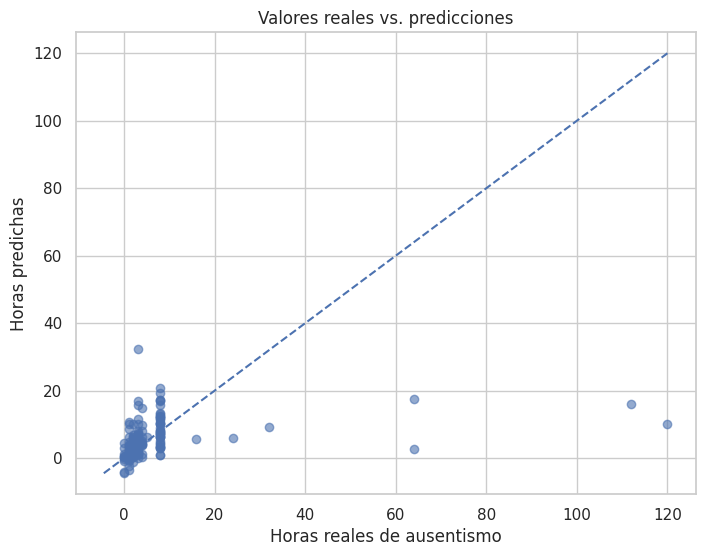

In [20]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.6
)

plt.xlabel("Horas reales de ausentismo")
plt.ylabel("Horas predichas")
plt.title("Valores reales vs. predicciones")

limite_min = min(y_test.min(), y_pred.min())
limite_max = max(y_test.max(), y_pred.max())

plt.plot(
    [limite_min, limite_max],
    [limite_min, limite_max],
    linestyle="--"
)

plt.show()

## 12. Predicción sobre nuevos datos

Una de las principales ventajas del pipeline construido es que permite realizar predicciones sobre nuevos registros sin repetir manualmente las etapas de preprocesamiento.

El nuevo registro se proporciona utilizando las variables originales del modelo. El pipeline se encarga internamente de aplicar la imputación, el escalado y la codificación correspondientes antes de generar la predicción.

Esta prueba permite verificar que el objeto final puede ser utilizado posteriormente en un escenario de inferencia.

In [21]:
nuevo_registro = pd.DataFrame({
    "Reason for Absence": [23],
    "Transportation Expense": [235],
    "Distance to Work": [20],
    "Age": [35],
    "Daily Work Load Average": [240.0],
    "Body Mass Index": [25],
    "Education": [1],
    "Children": [1],
    "Pets": [0],
    "Month": [7],
    "DayOfWeek": [2]
})

prediccion_nueva = model_pipeline.predict(nuevo_registro)

print("PREDICCIÓN SOBRE NUEVO REGISTRO")
print("=" * 50)

print(
    f"Horas estimadas de ausentismo: "
    f"{prediccion_nueva[0]:.2f}"
)

PREDICCIÓN SOBRE NUEVO REGISTRO
Horas estimadas de ausentismo: 4.69


## 13. Persistencia del pipeline

El pipeline entrenado se exporta utilizando la librería `joblib`.

Es importante destacar que no se almacena únicamente el modelo de Regresión Lineal. El archivo contiene el pipeline completo, incluyendo el `ColumnTransformer`, los imputadores, el escalador, el codificador y el estimador final.

Esto permite reutilizar posteriormente exactamente el mismo flujo utilizado durante el entrenamiento.

In [22]:
nombre_modelo = "pipeline_ausentismo.joblib"

joblib.dump(
    model_pipeline,
    nombre_modelo
)

print(f"Pipeline guardado correctamente: {nombre_modelo}")


Pipeline guardado correctamente: pipeline_ausentismo.joblib


In [23]:
# Cargamos nuevamente el pipeline guardado
pipeline_cargado = joblib.load(
    "pipeline_ausentismo.joblib"
)

# Volvemos a predecir utilizando el objeto recuperado
prediccion_recargada = pipeline_cargado.predict(
    nuevo_registro
)

print("PRUEBA DE REUTILIZACIÓN")
print("=" * 50)

print(
    f"Pipeline original: "
    f"{prediccion_nueva[0]:.2f} horas"
)

print(
    f"Pipeline recuperado: "
    f"{prediccion_recargada[0]:.2f} horas"
)

print(
    "\nLas predicciones coinciden:",
    np.allclose(
        prediccion_nueva,
        prediccion_recargada
    )
)

PRUEBA DE REUTILIZACIÓN
Pipeline original: 4.69 horas
Pipeline recuperado: 4.69 horas

Las predicciones coinciden: True


### Interpretación de los resultados

El modelo obtuvo un MAE de 5.8581 horas, lo que significa que las predicciones presentan, en promedio, un error absoluto aproximado de 5.86 horas respecto de los valores reales.

El RMSE fue de 15.0523 horas. El hecho de que esta métrica sea considerablemente mayor que el MAE indica que existen algunas observaciones con errores de predicción elevados. Esto se observa particularmente en registros con una cantidad elevada de horas de ausentismo.

El R² obtenido fue de 0.0638, por lo que el modelo de Regresión Lineal explica aproximadamente el 6.38 % de la variabilidad de las horas de ausentismo observada en el conjunto de prueba.

Por lo tanto, el desempeño predictivo del modelo base es limitado. La Regresión Lineal presenta dificultades para representar algunos patrones del dataset, especialmente frente a valores extremos.

También se observan algunas predicciones negativas. Estas no tienen una interpretación válida en términos de horas de ausentismo y constituyen una limitación adicional del modelo lineal.

Sin embargo, el objetivo principal de esta etapa no consiste en optimizar exhaustivamente el algoritmo predictivo, sino en desarrollar un flujo de Machine Learning consistente y reproducible, evitando data leakage y garantizando que las mismas transformaciones sean aplicadas durante el entrenamiento y la inferencia.

## 14. Conclusiones

En esta preentrega se desarrolló un flujo completo de Machine Learning para abordar la predicción de horas de ausentismo laboral.

El uso de `Pipeline` y `ColumnTransformer` permitió diferenciar el tratamiento de variables numéricas y categóricas y encapsular las diferentes etapas de preprocesamiento junto con el modelo predictivo.

Las variables numéricas fueron procesadas mediante imputación por mediana y estandarización, mientras que las variables categóricas fueron procesadas mediante imputación por moda y codificación One-Hot. Además, se utilizó `handle_unknown="ignore"` para permitir el procesamiento de categorías no observadas durante el entrenamiento.

Uno de los aspectos centrales del desarrollo fue la prevención del `data leakage`. La división entre entrenamiento y prueba se realizó antes de ajustar las transformaciones, de manera que los parámetros de imputación, escalado y codificación fueran aprendidos exclusivamente a partir del conjunto de entrenamiento.

Como modelo base se utilizó una Regresión Lineal. Los resultados obtenidos muestran una capacidad predictiva limitada, con un MAE de 5.8581 horas, un RMSE de 15.0523 horas y un R² de 0.0638. El análisis también evidenció dificultades frente a valores extremos y la aparición de algunas predicciones negativas.

A pesar de estas limitaciones predictivas, se cumplió el objetivo metodológico principal: construir un pipeline reproducible capaz de procesar los datos, entrenar el modelo y realizar inferencias sobre nuevos registros mediante un único objeto.

Finalmente, el pipeline completo fue persistido utilizando `joblib`, lo que permite conservar tanto las transformaciones aprendidas como el estimador y reutilizar el mismo flujo en futuras ejecuciones.

Como trabajo futuro se podrían comparar algoritmos capaces de modelar relaciones no lineales, analizar estrategias específicas para tratar los valores extremos y profundizar la optimización del desempeño predictivo.